# Interpretable Biodegradability Screening with Optimal Classification Trees — final (F1)

**Question:** can a small, understandable OCT predict ready biodegradability nearly as well as more flexible models?

## Flow

| Part | What happens | Data used |
|---|---|---|
| 1 | Load the three split files and check them | train / val / test |
| 2 | **Settings** (depths, leaf sizes, feature sets, tuning rules) | — |
| 3 | Evaluation functions | — |
| 4 | Fresh results table + always-NRB baseline | val |
| 5 | Sparse-regression feature selection (k = 3, 5, 10) | train |
| 6 | Model functions with the tuning rules | train (fit), val (tune) |
| 7 | Run every model on every feature set | train, val |
| 8 | Compare on validation | val |
| 9 | Depth check and the trees themselves | val |
| 10 | **Frozen settings for every model + suggested final picks** | — |
| 11 | **Test evaluation, run once** | test |
| 12 | **Testing prioritization: predict, then optimize** | test (labels hidden, then revealed) |
| 13 | **Screening tool for new chemicals** + saving the models | new data |

**Interpretation notes** (the boxes headed *What this shows*) sit directly below each result cell and explain why the numbers come out as they do. They quote the numbers from our run; the pipeline is seeded, so a rerun should reproduce them.

**Rule:** after changing anything in Part 2, rerun from Part 4 to Part 10. Part 4 resets everything, so runs never mix.

## What we maximize, and how tuning works

- **Main metric: validation balanced accuracy** = (NRB recall + RB specificity) / 2, which weights both classes equally. Plain accuracy is misleading (always-NRB gets 64%).
- **Secondary, practical view: NRB missed.** Calling an NRB chemical RB is the costlier mistake in screening, so tables also show NRB missed and RB cleared in chemicals.
- **Tree tuning (clean rule):** the grid search tries every max depth (2–4) × minimum leaf size × complexity. Instead of blindly taking the top validation AUC, we take the **simplest setting within `TOL_AUC` of the best** (lowest depth first, then largest leaf size). A tiny AUC gain is noise on 211 chemicals and not worth a bigger tree.
- **Logistic tuning:** ridge penalty with the lowest validation log-loss.
- **Threshold:** each model's threshold is the one with the best validation balanced accuracy, then **frozen** for test. (This matters for logistic regression; see Part 11.)
- **Final picks (Part 10):** for each model type, the **fewest-descriptor feature set within `TOL_BAL`** of that model's best validation balanced accuracy.

---
## Part 1 — Load and check the data

Three pre-made split files (633 / 211 / 211). Each is semicolon-separated with no header: 41 descriptors, then RB or NRB. We code **y = 1 for NRB**.

In [1]:
using CSV, DataFrames, Statistics, LinearAlgebra, Random
# IAI is preloaded by the IAI Julia kernel; if `IAI` is not defined, run: using IAI

const DESCRIPTORS = [
    "SpMax_L", "J_Dz(e)", "nHM", "F01[N-N]", "F04[C-N]", "NssssC", "nCb-",
    "C%", "nCp", "nO", "F03[C-N]", "SdssC", "HyWi_B(m)", "LOC", "SM6_L",
    "F03[C-O]", "Me", "Mi", "nN-N", "nArNO2", "nCRX3", "SpPosA_B(p)", "nCIR",
    "B01[C-Br]", "B03[C-Cl]", "N-073", "SpMax_A", "Psi_i_1d", "B04[C-Br]",
    "SdO", "TI2_L", "nCrt", "C-026", "F02[C-N]", "nHDon", "SpMax_B(m)",
    "Psi_i_A", "nN", "SM6_B(m)", "nArCOOR", "nX",
]

function read_part(path)
    d = CSV.read(path, DataFrame; delim = ';', header = false)
    @assert ncol(d) == 42 "$path has $(ncol(d)) columns"
    rename!(d, vcat(DESCRIPTORS, "class"))
    d.class = String.(strip.(string.(d.class)))
    @assert issubset(Set(d.class), Set(["NRB", "RB"]))
    d
end

train = read_part("biodeg_train.csv")
val   = read_part("biodeg_val.csv")
test  = read_part("biodeg_test.csv")

X_tr, X_va, X_te    = train[:, DESCRIPTORS], val[:, DESCRIPTORS], test[:, DESCRIPTORS]
ys_tr, ys_va, ys_te = train.class, val.class, test.class                  # labels for IAI
y_tr, y_va, y_te    = (Int.(s .== "NRB") for s in (ys_tr, ys_va, ys_te))  # 1 = NRB
nothing

In [2]:
for (name, d) in [("train", train), ("val", val), ("test", test)]
    nrb = count(==("NRB"), d.class)
    println(rpad(name, 6), nrow(d), " rows | NRB ", nrb, " (", round(100nrb / nrow(d), digits = 1),
            "%) | RB ", nrow(d) - nrb)
end
rowset(d) = Set(Tuple(r) for r in eachrow(d[:, DESCRIPTORS]))
println("\nRows shared between files (should all be 0): train-val ",
        length(intersect(rowset(train), rowset(val))), " | train-test ",
        length(intersect(rowset(train), rowset(test))), " | val-test ",
        length(intersect(rowset(val), rowset(test))))
println("Duplicate rows inside train: ", nrow(train) - length(rowset(train)))

train 633 rows | NRB 414 (65.4%) | RB 219
val   211 rows | NRB 135 (64.0%) | RB 76
test  211 rows | NRB 150 (71.1%) | RB 61

Rows shared between files (should all be 0): train-val 0 | train-test 0 | val-test 0
Duplicate rows inside train: 3


> ### What this shows
> - **Sizes 633 / 211 / 211, and no descriptor row appears in two files**, so nothing leaks between training, validation and test. The 3 duplicate rows (identical descriptors, possibly isomers) are all inside training.
> - **The class mix differs:** training 65.4% NRB, validation 64.0%, test 71.1%. The split was random, not stratified by class.
>
> **Why this matters later**
> 1. Plain accuracy is not comparable across sets: always predicting NRB scores 64% on validation but 71% on test.
> 2. Test has only 61 RB chemicals, so each RB mistake moves specificity by 1.6 points. Specificity is the noisiest test number.
> 3. A threshold tuned on a 64%-NRB validation set may not suit a 71%-NRB test set (Part 11, point 6).

---
## Part 2 — Settings (change only here)

- `MAX_DEPTHS = 2:4`: depth 5 overfit in v2 (validation AUC fell while training AUC rose), so trees are capped at 4.
- `RUN_SETS`: `"all"` = all 41 descriptors; `"sparse_kK"` = K descriptors chosen by sparse regression. Sparse sets use k = 3, 5 and 10.
- `TOL_AUC`: tree tuning picks the simplest setting within this much validation AUC of the best.
- `TOL_BAL`: final picks take the fewest-descriptor feature set within this much validation balanced accuracy of the best (0.015 ≈ 3 of 211 chemicals).

In [3]:
SEED       = 1
MAX_DEPTHS = 2:4
MINBUCKETS = [5, 10, 20]
LAMBDAS    = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
RUN_SETS   = ["all", "sparse_k3", "sparse_k5", "sparse_k10"]
TOL_AUC    = 0.01
TOL_BAL    = 0.015

0.015

---
## Part 3 — Evaluation functions

Every model gives **p = probability of NRB** per chemical.

- `metrics`: predict NRB when p ≥ threshold → accuracy, NRB recall, RB specificity, balanced accuracy.
- `best_threshold`: threshold with the best validation balanced accuracy (slightly optimistic on validation; test is the honest check).
- `auc`: chance that a random NRB chemical is ranked above a random RB chemical (threshold-free; matters for prioritization).

In [4]:
function metrics(p, y; t = 0.5)
    pred = p .>= t
    rec  = sum(pred .& (y .== 1)) / sum(y .== 1)
    spec = sum(.!pred .& (y .== 0)) / sum(y .== 0)
    (acc = mean(pred .== (y .== 1)), recall = rec, specificity = spec,
     bal_acc = (rec + spec) / 2,
     nrb_missed = sum(.!pred .& (y .== 1)), rb_cleared = sum(.!pred .& (y .== 0)))
end

function best_threshold(p, y)
    cands = sort(unique(vcat(p, 0.5)))
    cands[argmax([metrics(p, y; t = t).bal_acc for t in cands])]
end

function auc(p, y)
    pos, neg = p[y .== 1], p[y .== 0]
    sum((a > b) + 0.5 * (a == b) for a in pos, b in neg) / (length(pos) * length(neg))
end

auc (generic function with 1 method)

---
## Part 4 — Fresh results table and baseline

**Rerun from here after any change in Part 2.** One row per model with its validation scores **and every setting needed to reproduce it** (depth, leaf size, `cp`, ridge λ, threshold). This table becomes the frozen settings list in Part 10.

In [5]:
results = DataFrame(features = String[], model = String[], n_features = Int[],
                    max_depth = Union{Int,Missing}[], depth = Union{Int,Missing}[],
                    leaves = Union{Int,Missing}[], n_used = Int[],
                    minbucket = Union{Int,Missing}[], cp = Union{Float64,Missing}[],
                    lambda = Union{Float64,Missing}[], threshold = Float64[],
                    auc = Float64[], acc = Float64[], recall = Float64[],
                    specificity = Float64[], bal_acc = Float64[],
                    nrb_missed = Int[], rb_cleared = Int[], time_s = Float64[],
                    splits_on = String[])
models = Dict{Tuple{String,String},Any}()   # (feature set, model) => (fitted model, threshold)
grids  = Dict{Tuple{String,String},Any}()

function record!(fs_name, model, p_va; n_features, n_used, time_s, max_depth = missing,
                 depth = missing, leaves = missing, minbucket = missing, cp = missing,
                 lambda = missing, splits_on = "")
    t = best_threshold(p_va, y_va)
    m = metrics(p_va, y_va; t = t)
    push!(results, (fs_name, model, n_features, max_depth, depth, leaves, n_used, minbucket,
                    cp, lambda, t, auc(p_va, y_va), m.acc, m.recall, m.specificity, m.bal_acc,
                    m.nrb_missed, m.rb_cleared, time_s, splits_on))
    t
end

record!("none", "Always NRB", ones(length(y_va)); n_features = 0, n_used = 0, time_s = 0.0)
nothing

---
## Part 5 — Sparse-regression feature selection

Least squares with **at most k nonzero coefficients** (L0 / best subset, IAI optimal feature selection), fitted on **training only** with training-standardized descriptors. One selection per `sparse_kK` in `RUN_SETS`. Selection time is added to each model's time.

In [6]:
mu = [mean(X_tr[!, c]) for c in DESCRIPTORS]
sd = [std(X_tr[!, c]) for c in DESCRIPTORS]
sd[sd .== 0] .= 1.0
standardize(D) = DataFrame([(D[!, c] .- mu[j]) ./ sd[j]
                            for (j, c) in enumerate(DESCRIPTORS)], DESCRIPTORS)
Z_tr, Z_va, Z_te = standardize(X_tr), standardize(X_va), standardize(X_te)

feature_sets = Dict{String,Vector{String}}("all" => DESCRIPTORS)
fs_time      = Dict{String,Float64}("all" => 0.0)

for name in RUN_SETS
    startswith(name, "sparse_k") || continue
    k = parse(Int, replace(name, "sparse_k" => ""))
    ofs = IAI.OptimalFeatureSelectionRegressor(sparsity = k, random_seed = SEED)
    t0 = time()
    IAI.fit!(ofs, Z_tr, Float64.(y_tr))
    fs_time[name] = time() - t0
    w = Dict(String(f) => b for (f, b) in IAI.get_prediction_weights(ofs)[1])
    feature_sets[name] = [c for c in DESCRIPTORS if get(w, c, 0.0) != 0]
    println(rpad(name, 11), "(", length(feature_sets[name]), "): ", join(feature_sets[name], ", "))
end

[ Warning: This copy of Interpretable AI software is for academic purposes only and not for commercial use.


sparse_k3  (3): SpMax_L, SpPosA_B(p), F02[C-N]
sparse_k5  (5): SpMax_L, LOC, SpPosA_B(p), B03[C-Cl], nN
sparse_k10 (10): SpMax_L, C%, nO, HyWi_B(m), LOC, F03[C-O], Mi, SpPosA_B(p), B03[C-Cl], F02[C-N]


> ### What this shows, and why
> | k | Descriptors selected |
> |---|---|
> | 3 | SpMax_L, SpPosA_B(p), F02[C-N] |
> | 5 | SpMax_L, LOC, SpPosA_B(p), B03[C-Cl], nN |
> | 10 | SpMax_L, C%, nO, HyWi_B(m), LOC, F03[C-O], Mi, SpPosA_B(p), B03[C-Cl], F02[C-N] |
>
> - **SpMax_L and SpPosA_B(p) are in every set:** they have the strongest *linear* relationship with NRB (roughly, branching and polarizable atoms).
> - **The sets are not nested** (F02[C-N] is in the 3-set, drops out of the 5-set, returns in the 10-set). That is what an exact best-subset (L0) search does: the best 5 descriptors are not simply the best 3 plus two more. Greedy or lasso-style selection would usually add descriptors one at a time.
> - **Never selected: SpMax_B(m) and F04[C-N].** Yet these become the root split and the cleanest (100% NRB) leaf of the full-feature OCT (Part 9). Why: sparse regression ranks descriptors by their contribution to a *linear least-squares* fit. These two act as *thresholds* (F04[C-N] is 0 for most chemicals and strongly NRB above 1.5), and their linear information overlaps with descriptors already chosen. A good linear feature is not the same as a good tree feature, which is why feature selection hurts the trees later.
> - The 41 descriptors were already selected by Mansouri et al. from 781, so little redundancy is left to remove.

---
## Part 6 — Model functions and the tuning rules

**Trees.** `fit_tree` runs the IAI grid search over `MAX_DEPTHS` × `MINBUCKETS` (IAI tunes `cp` for each combination) on validation AUC. Then `choose_config` applies the clean rule: **keep every setting within `TOL_AUC` of the best validation AUC, and take the simplest** (lowest max depth, then largest leaf size). That exact setting (depth, leaf size, `cp`) is refit on **training only**. `greedy = true` gives CART (no local search); `greedy = false` gives OCT.

**Logistic regression.** Ridge-penalized, fitted by Newton's method on standardized descriptors (intercept not penalized); λ chosen by validation log-loss.

In [7]:
tree_depth(lnr, n = 1) = IAI.is_leaf(lnr, n) ? 0 :
    1 + max(tree_depth(lnr, IAI.get_lower_child(lnr, n)), tree_depth(lnr, IAI.get_upper_child(lnr, n)))
tree_leaves(lnr)   = count(n -> IAI.is_leaf(lnr, n), 1:IAI.get_num_nodes(lnr))
tree_features(lnr) = unique([String(IAI.get_split_feature(lnr, n))
                             for n in 1:IAI.get_num_nodes(lnr) if !IAI.is_leaf(lnr, n)])

function choose_config(grid)
    g = IAI.get_grid_result_summary(grid)
    best_auc = maximum(g.valid_score)
    ok = g[g.valid_score .>= best_auc - TOL_AUC, :]
    sort!(ok, [:max_depth, order(:minbucket, rev = true), order(:valid_score, rev = true)])
    ok[1, :], best_auc
end

function fit_tree(fs; greedy = false)
    t0 = time()
    grid = IAI.GridSearch(
        IAI.OptimalTreeClassifier(random_seed = SEED, localsearch = !greedy),
        max_depth = MAX_DEPTHS, minbucket = MINBUCKETS)
    IAI.fit!(grid, X_tr[:, fs], ys_tr, X_va[:, fs], ys_va, validation_criterion = :auc)
    row, best_auc = choose_config(grid)

    lnr = IAI.OptimalTreeClassifier(random_seed = SEED, localsearch = !greedy,
                                    max_depth = row.max_depth, minbucket = row.minbucket,
                                    cp = row.cp)
    IAI.fit!(lnr, X_tr[:, fs], ys_tr)                  # refit on training only
    p_va = IAI.predict_proba(lnr, X_va[:, fs])[!, "NRB"]
    lnr, grid, row, p_va, time() - t0
end

fit_tree (generic function with 1 method)

In [8]:
function ridge_logit(Z, y, lambda; iters = 100)
    A = hcat(ones(size(Z, 1)), Matrix(Z))
    P = Diagonal(vcat(0.0, fill(lambda, size(Z, 2))))
    b = zeros(size(A, 2))
    for _ in 1:iters
        p = 1 ./ (1 .+ exp.(-A * b))
        step = (A' * (A .* (p .* (1 .- p))) + P) \ (A' * (y .- p) - P * b)
        b .+= step
        norm(step) < 1e-8 && break
    end
    b
end
predict_logit(b, Z) = 1 ./ (1 .+ exp.(-(hcat(ones(size(Z, 1)), Matrix(Z)) * b)))

function fit_logit(fs)
    t0 = time()
    best_lambda, best_loss = NaN, Inf
    for lambda in LAMBDAS
        p = clamp.(predict_logit(ridge_logit(Z_tr[:, fs], Float64.(y_tr), lambda),
                                 Z_va[:, fs]), 1e-12, 1 - 1e-12)
        loss = -mean(y_va .* log.(p) .+ (1 .- y_va) .* log.(1 .- p))
        if loss < best_loss
            best_lambda, best_loss = lambda, loss
        end
    end
    b = ridge_logit(Z_tr[:, fs], Float64.(y_tr), best_lambda)
    b, best_lambda, predict_logit(b, Z_va[:, fs]), time() - t0
end

fit_logit (generic function with 1 method)

---
## Part 7 — Run every model on every feature set

**Timing note:** Julia compiles on first use, so the first run's times are inflated. For the report, rerun Parts 4–7 once and use the second run's times.

In [9]:
for fs_name in RUN_SETS
    fs = feature_sets[fs_name]
    for (name, greedy) in [("CART", true), ("OCT", false)]
        lnr, grid, row, p, t = fit_tree(fs; greedy = greedy)
        used = tree_features(lnr)
        thr = record!(fs_name, name, p; n_features = length(fs),
                      max_depth = row.max_depth, depth = tree_depth(lnr), leaves = tree_leaves(lnr),
                      n_used = length(used), minbucket = row.minbucket, cp = row.cp,
                      time_s = t + fs_time[fs_name], splits_on = join(used, ", "))
        models[(fs_name, name)] = (lnr, thr)
        grids[(fs_name, name)]  = grid
    end
    b, lambda, p, t = fit_logit(fs)
    thr = record!(fs_name, "Logistic", p; n_features = length(fs), n_used = length(fs),
                  lambda = lambda, time_s = t + fs_time[fs_name])
    models[(fs_name, "Logistic")] = (b, thr)
end
println("Fitted ", nrow(results) - 1, " models.")

Fitted 12 models.


---
## Part 8 — Compare on validation

**Table A**: all models, sorted by balanced accuracy, with NRB missed / RB cleared in chemicals (135 NRB, 76 RB in validation).
**Table B**: balanced accuracy, model × feature set. Read across a row for the effect of feature selection.
**Table C**: NRB missed, model × feature set (the precautionary view; lower is better).

In [10]:
fs_order = Dict(n => i for (i, n) in enumerate(vcat("none", RUN_SETS)))
ordered(df) = sort(df, [order(:features, by = x -> fs_order[x]), :model])

tblA = sort(select(results, :model, :features, :n_features, :max_depth, :leaves, :n_used,
                   :threshold, :auc, :recall, :specificity, :bal_acc, :nrb_missed, :rb_cleared),
            :bal_acc, rev = true)
for c in [:threshold, :auc, :recall, :specificity, :bal_acc]
    tblA[!, c] = round.(tblA[!, c], digits = 3)
end
println("Table A — validation results (sorted by balanced accuracy)")
show(tblA, allrows = true, allcols = true, eltypes = false, summary = false)
CSV.write("validation_results_v3.csv", results)
println()

Table A — validation results (sorted by balanced accuracy)
 Row │ model       features    n_features  max_depth  leaves   n_used  threshold  auc    recall  specificity  bal_acc  nrb_missed  rb_cleared 
─────┼────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
   1 │ Logistic    all                 41    missing  missing      41      0.489  0.927   0.941        0.789    0.865           8          60
   2 │ OCT         all                 41          4        9       7      0.5    0.897   0.889        0.816    0.852          15          62
   3 │ Logistic    sparse_k10          10    missing  missing      10      0.689  0.916   0.785        0.895    0.84           29          68
   4 │ Logistic    sparse_k5            5    missing  missing       5      0.741  0.898   0.733        0.934    0.834          36          71
   5 │ Logistic    sparse_k3            3    missing  missing       3      0.691  0.876

> ### What this shows (validation)
> - **Logistic regression on all 41 descriptors is best:** balanced accuracy 0.865, AUC 0.927, missing only 8 of 135 NRB chemicals.
> - **The full-feature OCT is close:** 0.852, i.e. 182 vs. 187 chemicals correct, using 7 descriptors in a 9-leaf tree. It clears slightly more RB chemicals than logistic regression (62 vs. 60 of 76).
> - **Every model is far above always-NRB** (0.5).
> - **Why tree thresholds are 0.5:** a tree's score is its leaf's NRB share, and leaf shares sit far from 0.5 (e.g. 0.21, 0.72, 0.89). Any threshold between two leaf values gives identical predictions, so tuning rarely changes anything for trees.
> - **Why some logistic thresholds are 0.69–0.74:** logistic regression gives every chemical its own score, so the threshold can be fitted very closely to these 211 validation chemicals. Thresholds that far from 0.5 are a warning sign of overfitting to validation, and Part 11 confirms it.
> - Validation scores are optimistic in general, because settings and thresholds were chosen on this same data.

In [11]:
cols = vcat(["model"], [n for n in RUN_SETS])
mk_pivot(v) = select(unstack(filter(r -> r.features != "none", results), :model, :features, v;
                             combine = last), intersect(cols, ["model"; RUN_SETS])...)

pB = mk_pivot(:bal_acc)
for c in RUN_SETS; pB[!, c] = round.(pB[!, c], digits = 3); end
println("Table B — validation balanced accuracy (higher is better)")
show(pB, allcols = true, eltypes = false, summary = false)

println("\n\nTable C — validation NRB missed out of $(sum(y_va)) (lower is better)")
show(mk_pivot(:nrb_missed), allcols = true, eltypes = false, summary = false)
println()

Table B — validation balanced accuracy (higher is better)
 Row │ model     all    sparse_k3  sparse_k5  sparse_k10 
─────┼───────────────────────────────────────────────────
   1 │ CART      0.82       0.793      0.798       0.817
   2 │ OCT       0.852      0.817      0.826       0.819
   3 │ Logistic  0.865      0.827      0.834       0.84

Table C — validation NRB missed out of 135 (lower is better)
 Row │ model     all  sparse_k3  sparse_k5  sparse_k10 
─────┼─────────────────────────────────────────────────
   1 │ CART       13         24         19          21
   2 │ OCT        15         14         22          15
   3 │ Logistic    8         29         36          29


> ### What this shows
> **Table B (balanced accuracy):**
> - **Every model is best with all 41 descriptors.** Logistic regression drops 0.025–0.038 with sparse sets, OCT 0.026–0.035, CART 0.003–0.027.
>   - Trees lose the threshold-type descriptors they need (Part 5).
>   - Logistic regression loses information it uses additively across many descriptors.
> - **OCT ≥ CART at every feature set on validation:** all 0.852 vs. 0.820; k=3 0.817 vs. 0.793; k=5 0.826 vs. 0.798; k=10 0.819 vs. 0.817.
>
> **Table C (NRB missed, the precautionary view):**
> - Logistic regression on all features misses the fewest (8), but sparse logistic regression misses 29–36, because of its high thresholds.
> - **OCT is stable: 14–22 missed across all feature sets.** The 3-descriptor OCT misses 14, as few as the full OCT (15). Why: its structure is cautious (see the tree in Part 9).

---
## Part 9 — Depth check and the trees

**Table D**: for every tree, the best validation AUC at each depth, plus the setting the clean rule actually chose. If depth 4 adds less than `TOL_AUC` over depth 3, the rule picks depth 3.

In [12]:
for fs_name in RUN_SETS, name in ("OCT", "CART")
    g = IAI.get_grid_result_summary(grids[(fs_name, name)])
    per_depth = sort(combine(groupby(sort(g, :valid_score, rev = true), :max_depth), first), :max_depth)
    r = filter(x -> x.features == fs_name && x.model == name, results)[1, :]
    println("\n$name | $fs_name — best AUC by depth: ",
            join(["d$(x.max_depth): $(round(x.valid_score, digits = 3)) (train $(round(x.train_score, digits = 3)))"
                  for x in eachrow(per_depth)], " | "))
    println("   chosen: max_depth=$(r.max_depth), minbucket=$(r.minbucket), cp=$(round(r.cp, sigdigits = 3)) ",
            "→ depth $(r.depth), $(r.leaves) leaves, splits on: $(r.splits_on)")
end


OCT | all — best AUC by depth: d2: 0.758 (train 0.812) | d3: 0.828 (train 0.856) | d4: 0.855 (train 0.872)
   chosen: max_depth=4, minbucket=20, cp=0.00457 → depth 4, 9 leaves, splits on: SpMax_B(m), F02[C-N], SpPosA_B(p), SpMax_L, Psi_i_A, F04[C-N], SdssC

CART | all — best AUC by depth: d2: 0.781 (train 0.812) | d3: 0.803 (train 0.845) | d4: 0.853 (train 0.867)
   chosen: max_depth=4, minbucket=10, cp=0.00342 → depth 4, 11 leaves, splits on: SpMax_B(m), F02[C-N], SpMax_L, LOC, F03[C-O], nArCOOR, HyWi_B(m), SdssC

OCT | sparse_k3 — best AUC by depth: d2: 0.751 (train 0.784) | d3: 0.842 (train 0.842) | d4: 0.837 (train 0.864)
   chosen: max_depth=3, minbucket=20, cp=0.00913 → depth 3, 4 leaves, splits on: F02[C-N], SpMax_L, SpPosA_B(p)

CART | sparse_k3 — best AUC by depth: d2: 0.755 (train 0.782) | d3: 0.773 (train 0.809) | d4: 0.823 (train 0.847)
   chosen: max_depth=4, minbucket=20, cp=0.0183 → depth 4, 7 leaves, splits on: SpPosA_B(p), SpMax_L, F02[C-N]

OCT | sparse_k5 — best AUC

> ### What this shows: depth, and optimal vs. greedy
> - **Depth 2 is always too shallow** (validation AUC 0.75–0.79). Two questions per chemical can't express the RB profile, which needs three conditions together (see the 4-leaf tree below).
> - **With all 41 descriptors, both trees go to depth 4.** Depth 3 → 4 gains about 0.03 AUC for OCT (0.828 → 0.855) and 0.05 for CART (0.803 → 0.853), more than the 0.01 tolerance, because 41 descriptors offer more structure to use.
> - **On sparse sets, OCT stops at depth 3.** With only 3–5 useful descriptors, depth 4 adds nothing and can overfit (k=10: validation 0.846 → 0.834 while training rises 0.850 → 0.870).
> - **The key optimal-vs-greedy evidence, at the same depth 3:**
>
>   | Features | OCT | CART |
>   |---|---|---|
>   | 3 descriptors | 0.842 | 0.773 |
>   | 5 descriptors | 0.858 | 0.774 |
>
>   CART needs depth 4 (more leaves) to catch up. **Why:** CART picks each split greedily and can never revisit an early choice. OCT optimizes the whole tree at once, so it can choose a first split that looks worse alone but sets up much better splits below it.
> - **Where the gap closes:** with all 41 descriptors, both trees find the same strong root split (SpMax_B(m)), so they end up similar (0.855 vs. 0.853). On k=10, CART at depth 3 (0.851) ties OCT (0.846) within noise.

**Print a tree.** Change `key` to any (feature set, model) pair. Leaves show predicted class, %, training counts [NRB, RB] and number of chemicals.

In [13]:
key = ("sparse_k3", "OCT")
lnr = models[key][1]
println("Tree: $(key[2]) on $(key[1]) — depth $(tree_depth(lnr)), $(tree_leaves(lnr)) leaves, ",
        "splits on: ", join(tree_features(lnr), ", "))
println("Validation threshold: ", models[key][2], "\n")
show(stdout, MIME("text/plain"), lnr)
println()
IAI.write_html("tree_$(key[1])_$(key[2]).html", lnr)

Tree: OCT on sparse_k3 — depth 3, 4 leaves, splits on: F02[C-N], SpMax_L, SpPosA_B(p)
Validation threshold: 0.5

Fitted OptimalTreeClassifier:
  1) Split: F02[C-N] < 1.5
    2) Split: SpMax_L < 5.101
      3) Split: SpPosA_B(p) < 1.266
        4) Predict: RB (79.19%), [41,156], 197 points, error 0.2081
        5) Predict: NRB (77.27%), [85,25], 110 points, error 0.2273
      6) Predict: NRB (89.83%), [106,12], 118 points, error 0.1017
    7) Predict: NRB (87.50%), [182,26], 208 points, error 0.125


617076

> ### What this shows: the 4-leaf OCT on 3 descriptors
> Rules (training counts):
> 1. **F02[C-N] ≥ 1.5 → NRB** (208 chemicals, 88% NRB)
> 2. otherwise, **SpMax_L ≥ 5.101 → NRB** (118 chemicals, 90% NRB)
> 3. otherwise, **SpPosA_B(p) ≥ 1.266 → NRB** (110 chemicals, 77% NRB)
> 4. otherwise → **RB** (197 chemicals, 79% RB)
>
> - **Plain reading** (check each descriptor against Table 7 and Sections 3.3–3.4 of Mansouri et al.): more carbon–nitrogen pairs (nitrogen substitution), more branching, or more easily polarized atoms → the chemical tends to fail the screen. Small, unbranched, low-nitrogen molecules tend to pass. These are associations, not causes.
> - **Why it catches NRB well but clears fewer RB:** 3 of its 4 leaves predict NRB, and a chemical is called RB only if it passes all three tests. That keeps NRB recall high and lowers RB specificity. The full OCT's extra leaves carve small RB pockets out of NRB-leaning regions, which improves specificity.
> - **Where errors concentrate:** the rule-3 leaf (77% NRB) is the least pure, and the RB leaf (rule 4) still contains 41 NRB chemicals, which are the NRB chemicals this tree misses.

---
## Part 10 — Frozen settings and final picks (before test)

**Table E** lists every model's exact settings, chosen on validation. These are frozen: Part 11 uses the stored fitted models and thresholds as they are, with no refitting or retuning. The table is saved to `final_settings_v3.csv` so you have a record made *before* seeing test results.

**Table F** applies the pick rule for each model type: the **fewest-descriptor feature set within `TOL_BAL` of that model's best validation balanced accuracy**. These are the suggested headline models; write your final choices and reasons in the markdown cell after it.

In [14]:
tblE = ordered(select(filter(r -> r.features != "none", results),
                      :model, :features, :n_features, :max_depth, :depth, :leaves, :minbucket,
                      :cp, :lambda, :threshold, :auc, :bal_acc, :splits_on))
tblE.cp        = [ismissing(x) ? missing : round(x, sigdigits = 3) for x in tblE.cp]
tblE.threshold = round.(tblE.threshold, digits = 3)
tblE.auc       = round.(tblE.auc, digits = 3)
tblE.bal_acc   = round.(tblE.bal_acc, digits = 3)
println("Table E — frozen settings for every model (validation-chosen)")
show(tblE, allrows = true, allcols = true, eltypes = false, summary = false, truncate = 0)
CSV.write("final_settings_v3.csv", tblE)
println()

Table E — frozen settings for every model (validation-chosen)
 Row │ model     features    n_features  max_depth  depth    leaves   minbucket  cp             lambda       threshold  auc    bal_acc  splits_on                                                               
─────┼──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
   1 │ CART      all                 41          4        4       11         10        0.00342  missing          0.769  0.853    0.82   SpMax_B(m), F02[C-N], SpMax_L, LOC, F03[C-O], nArCOOR, HyWi_B(m), SdssC
   2 │ Logistic  all                 41    missing  missing  missing    missing  missing             10.0        0.489  0.927    0.865
   3 │ OCT       all                 41          4        4        9         20        0.00457  missing          0.5    0.897    0.852  SpMax_B(m), F02[C-N], SpPosA_B(p), SpMax_

> ### What this shows
> - **OCT:** depth 4 with 9 leaves on all features; depth 3 with 4–6 leaves on the sparse sets.
> - **CART usually needs more leaves for the same features** (all: 11 vs. 9; 3 descriptors: 7 vs. 4; 5 descriptors: 8 vs. 6). That's the simplicity advantage of optimizing the whole tree.
> - **Logistic λ:** 10 for all features and k=10, 0.001 for k=3 and k=5. Why: more descriptors means more correlated descriptors, which need more shrinkage to keep coefficients stable; with 3–5 descriptors almost no regularization is needed.
> - These settings are saved to `final_settings_v3.csv` and frozen before test.

In [15]:
picks = DataFrame(model = String[], features = String[], n_features = Int[],
                  val_bal_acc = Float64[], best_val_bal_acc = Float64[])
for name in ("CART", "OCT", "Logistic")
    sub = filter(r -> r.model == name, results)
    best = maximum(sub.bal_acc)
    close = sort(sub[sub.bal_acc .>= best - TOL_BAL, :], [:n_features, order(:bal_acc, rev = true)])
    r = close[1, :]
    push!(picks, (name, r.features, r.n_features, round(r.bal_acc, digits = 3), round(best, digits = 3)))
end
println("Table F — suggested picks (fewest descriptors within TOL_BAL = $TOL_BAL of each model's best)")
show(picks, eltypes = false, summary = false)
PICKS = Set(zip(picks.features, picks.model))
println()

Table F — suggested picks (fewest descriptors within TOL_BAL = 0.015 of each model's best)
 Row │ model     features    n_features  val_bal_acc  best_val_bal_acc 
─────┼─────────────────────────────────────────────────────────────────
   1 │ CART      sparse_k10          10        0.817             0.82
   2 │ OCT       all                 41        0.852             0.852
   3 │ Logistic  all                 41        0.865             0.865


> ### What this shows
> - **OCT → all features:** no sparse OCT is within 0.015 of 0.852.
> - **Logistic → all features:** no sparse version is within 0.015 of 0.865.
> - **CART → k=10:** its score (0.817) is within 0.015 of CART's best (0.820), and it uses fewer descriptors, so the rule prefers it.
>
> The rule favors fewer descriptors when validation scores are nearly tied. Whether a near-tie on 211 chemicals is real is exactly what the test set checks (Part 11, point 7).

*Final choices (from the pre-set pick rule, plus one model reported for interpretability):*

- **CART:** 10 sparse descriptors. Fewest descriptors within 0.015 of CART's best validation score (0.817 vs. 0.820).
- **OCT (main interpretable model):** all features. No sparse OCT came within 0.015 of 0.852.
- **Logistic regression:** all features. No sparse version came within 0.015 of 0.865.
- **Also reported:** the OCT on 3 descriptors (4 leaves), as the most interpretable model. It was not chosen by score.

---
## Part 11 — Test evaluation (run once, at the very end)

Set `RUN_TEST = true` only when Part 10 is final. Every model is applied to test **with its frozen validation threshold**; nothing is refit. All models are reported for completeness, but the headline comparison is the **pre-chosen picks** (marked `pick = true`). Do not change models or picks based on these numbers.

Test has 150 NRB and 61 RB (71% NRB, more than validation), so compare balanced accuracy rather than plain accuracy across the two sets.

In [16]:
RUN_TEST = true

if RUN_TEST
    test_results = DataFrame(features = String[], model = String[], n_features = Int[],
                             pick = Bool[], val_bal_acc = Float64[], threshold = Float64[],
                             auc = Float64[], acc = Float64[], recall = Float64[],
                             specificity = Float64[], bal_acc = Float64[],
                             nrb_missed = Int[], rb_cleared = Int[])
    m0 = metrics(ones(length(y_te)), y_te)
    push!(test_results, ("none", "Always NRB", 0, false, 0.5, 0.5, 0.5, m0.acc, m0.recall,
                         m0.specificity, m0.bal_acc, m0.nrb_missed, m0.rb_cleared))

    for r in eachrow(filter(x -> x.features != "none", results))
        fs = feature_sets[r.features]
        obj, thr = models[(r.features, r.model)]
        p = r.model == "Logistic" ? predict_logit(obj, Z_te[:, fs]) :
                                    IAI.predict_proba(obj, X_te[:, fs])[!, "NRB"]
        m = metrics(p, y_te; t = thr)
        push!(test_results, (r.features, r.model, r.n_features, (r.features, r.model) in PICKS,
                             r.bal_acc, thr, auc(p, y_te), m.acc, m.recall, m.specificity,
                             m.bal_acc, m.nrb_missed, m.rb_cleared))
    end
    for c in [:val_bal_acc, :threshold, :auc, :acc, :recall, :specificity, :bal_acc]
        test_results[!, c] = round.(test_results[!, c], digits = 3)
    end
    CSV.write("test_results_v3.csv", test_results)

    println("Test set: $(sum(y_te)) NRB, $(sum(1 .- y_te)) RB\n")
    for fs_name in vcat("none", RUN_SETS)
        println("=== Test results | features: $fs_name ===")
        show(select(filter(r -> r.features == fs_name, test_results), Not(:features)),
             allcols = true, eltypes = false, summary = false)
        println("\n")
    end

    println("=== Headline: pre-chosen picks on test ===")
    show(filter(r -> r.pick || r.model == "Always NRB", test_results),
         allcols = true, eltypes = false, summary = false)
    println("\n")

    pT = select(unstack(filter(r -> r.features != "none", test_results), :model, :features, :bal_acc;
                        combine = last), intersect(cols, ["model"; RUN_SETS])...)
    println("=== Test balanced accuracy, model × feature set ===")
    show(pT, allcols = true, eltypes = false, summary = false)
    println()
else
    println("Test evaluation is switched off (RUN_TEST = false).")
end

Test set: 150 NRB, 61 RB

=== Test results | features: none ===
 Row │ model       n_features  pick   val_bal_acc  threshold  auc  acc    recall  specificity  bal_acc  nrb_missed  rb_cleared 
─────┼─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
   1 │ Always NRB           0  false          0.5        0.5  0.5  0.711     1.0          0.0      0.5           0           0

=== Test results | features: all ===
 Row │ model     n_features  pick   val_bal_acc  threshold  auc    acc    recall  specificity  bal_acc  nrb_missed  rb_cleared 
─────┼─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
   1 │ CART              41  false        0.82       0.769  0.857  0.853   0.88         0.787    0.833          18          48
   2 │ OCT               41   true        0.852      0.5    0.838  0.829   0.853        0.77     0.812          22          47
   3 

> ### What this shows (test)
> | Model | Validation | Test | Test AUC | NRB missed /150 | RB cleared /61 |
> |---|---|---|---|---|---|
> | Logistic, all | 0.865 | 0.812 | **0.904** | 17 | 45 |
> | OCT, all | 0.852 | 0.812 | 0.838 | 22 | 47 |
> | CART, all | 0.820 | 0.833 | 0.857 | 18 | 48 |
> | OCT, 3 descriptors (4 leaves) | 0.817 | 0.768 | 0.783 | 23 | 42 |
> | Always NRB | 0.500 | 0.500 | 0.500 | 0 | 0 |
>
> 1. **Scores dropped from validation to test**, for three reasons: settings, thresholds and feature sets were chosen on validation (so winners are partly lucky); test has more NRB (71% vs. 64%) and only 61 RB; and 211 chemicals is a small, noisy sample (roughly ±0.03).
> 2. **On all features, the three models tie on classification** (0.812–0.833, within noise). The signal sits in a few strong structural descriptors that a well-built tree captures, and 633 training chemicals limit what extra flexibility can add.
> 3. **Logistic regression ranks clearly better** (AUC 0.904 vs. 0.838 and 0.857). A 9- or 11-leaf tree gives only 9–11 distinct scores, so chemicals in a leaf tie; logistic regression orders every chemical and combines effects gradually instead of with hard cutoffs. Classification only asks which side of a line a chemical falls on; ranking asks which is more likely. This matters for Part 12.
> 4. **OCT beats CART on every sparse set, with fewer leaves:** 3 descriptors 0.768 vs. 0.736; 5 descriptors 0.804 vs. 0.764; 10 descriptors 0.769 vs. 0.718. This matches the depth evidence in Part 9. CART won on all features (0.833 vs. 0.812), within noise, where both trees found the same root split.
> 5. **Sparse selection hurts the trees on test too** (OCT 0.768–0.804 vs. 0.812; CART 0.718–0.764 vs. 0.833): the threshold-type descriptors they rely on were never selected (Part 5).
> 6. **Logistic regression on 5 descriptors missed 61 of 150 NRB chemicals, although its AUC (0.817) was reasonable.** Its validation threshold of 0.741 predicts NRB only when very confident. On a test set with 71% NRB, that labels many NRB chemicals as RB. The ranking is fine; the cutoff didn't transfer.
> 7. **The CART pick (10 descriptors) fell from 0.817 to 0.718.** Its validation near-tie with the full CART (0.817 vs. 0.820) did not hold up: choosing among options on 211 chemicals rewards luck.
> 8. **The 4-leaf OCT gives the same NRB protection as the full OCT** (23 vs. 22 missed) and gives up RB chemicals (42 vs. 47 cleared), the same pattern as on validation, so this is a stable finding. The OCT on 5 descriptors (6 leaves, 3 descriptors used) scored 0.804; report that as an observation, since it was not a pre-chosen model.
>
> **Bottom line:** small OCTs match more flexible models at *classifying* chemicals and beat greedy CART with simpler trees, but they rank chemicals less finely, and linear feature selection discards the threshold-type descriptors trees rely on.

---
## Part 12 — Testing prioritization (predict, then optimize)

**The decision.** A lab has an untested batch of chemicals and can afford only **B** tests. It wants to find as many NRB chemicals (screen failures) as possible, so they can be prioritized for further assessment.

**Predict.** Each frozen model gives p̂ᵢ = estimated probability that chemical i is NRB (for a tree, the NRB share of its leaf in training).

**Optimize.** Choose z ∈ {0,1}ᴺ with Σ zᵢ ≤ B to maximize Σ p̂ᵢ zᵢ, the expected number of NRB chemicals found. With equal test costs and equal value per discovery, the optimal solution is exactly: **test the B chemicals with the highest p̂ᵢ**.

**Evaluation.** The test set plays the untested batch: labels are hidden while selecting, then revealed to count discoveries. We compare against **random selection** with the same budget (repeated many times) and against a **perfect oracle** (min(B, #NRB)). Trees give only a few distinct scores, so many chemicals tie; ties are broken at random and repeated, and we report the average and range.

**Reading the table.** `nrb_found` = average NRB chemicals found; `precision` = share of tested chemicals that were NRB; `share_of_all_nrb` = share of all NRB in the batch that were found; `lift` = found ÷ random. Test is 71% NRB, so random already reaches ~71% precision and the maximum possible lift is about 1.4.

Nothing is refit or retuned here; models and settings are the frozen ones from Part 10. Testing confirms a label, it does not change biodegradability, and this measures testing efficiency, not environmental harm avoided.

In [17]:
PRESCRIBE = [("all", "Logistic"), ("all", "OCT"), ("all", "CART"),
             ("sparse_k3", "OCT"), ("sparse_k5", "OCT")]   # (feature set, model) to compare
BUDGETS   = [0.10, 0.20, 0.30]                            # share of the batch that can be tested
N_REPEATS = 1000                                          # random draws / tie-breaks

function scores_on(key, Xraw)
    fs = feature_sets[key[1]]
    obj, _ = models[key]
    key[2] == "Logistic" ? predict_logit(obj, standardize(Xraw)[:, fs]) :
                           IAI.predict_proba(obj, Xraw[:, fs])[!, "NRB"]
end

# Optimal selection for a budget B: the B highest scores, ties broken at random
top_B(p, B, rng) = sortperm(collect(zip(p, rand(rng, length(p)))), rev = true)[1:B]

rng = MersenneTwister(SEED)
N, K = length(y_te), sum(y_te)
test_scores = Dict(key => scores_on(key, X_te) for key in PRESCRIBE)

presc = DataFrame(budget = String[], B = Int[], method = String[],
                  distinct_scores = Union{Int,Missing}[], nrb_found = Float64[],
                  low = Int[], high = Int[], precision = Float64[],
                  share_of_all_nrb = Float64[], lift = Float64[])

for f in BUDGETS
    B = round(Int, f * N)
    rand_counts = [sum(y_te[randperm(rng, N)[1:B]]) for _ in 1:N_REPEATS]
    rmean = mean(rand_counts)
    push!(presc, ("$(round(Int, 100f))%", B, "Random", missing, rmean,
                  round(Int, quantile(rand_counts, 0.025)), round(Int, quantile(rand_counts, 0.975)),
                  rmean / B, rmean / K, 1.0))
    for key in PRESCRIBE
        p = test_scores[key]
        counts = [sum(y_te[top_B(p, B, rng)]) for _ in 1:N_REPEATS]
        m = mean(counts)
        push!(presc, ("$(round(Int, 100f))%", B, "$(key[2]) ($(key[1]))", length(unique(p)), m,
                      minimum(counts), maximum(counts), m / B, m / K, m / rmean))
    end
    best = min(B, K)
    push!(presc, ("$(round(Int, 100f))%", B, "Perfect (oracle)", missing, best, best, best,
                  best / B, best / K, best / rmean))
end
for c in [:nrb_found, :precision, :share_of_all_nrb, :lift]
    presc[!, c] = round.(presc[!, c], digits = 3)
end
println("Test batch: $N chemicals, $K NRB ($(round(100K / N, digits = 1))%)\n")
println("Table G — NRB chemicals found under each testing budget (low/high = range over tie-breaks; 95% range for Random)")
show(presc, allrows = true, allcols = true, eltypes = false, summary = false)
CSV.write("prioritization_v4.csv", presc)
println()

Test batch: 211 chemicals, 150 NRB (71.1%)

Table G — NRB chemicals found under each testing budget (low/high = range over tie-breaks; 95% range for Random)
 Row │ budget  B   method            distinct_scores  nrb_found  low  high  precision  share_of_all_nrb  lift  
─────┼─────────────────────────────────────────────────────────────────────────────────────────────────────────
   1 │ 10%     21  Random                    missing     15.001   11    19      0.714             0.1    1.0
   2 │ 10%     21  Logistic (all)                211     21.0     21    21      1.0               0.14   1.4
   3 │ 10%     21  OCT (all)                       9     19.575   19    21      0.932             0.13   1.305
   4 │ 10%     21  CART (all)                     10     20.084   18    21      0.956             0.134  1.339
   5 │ 10%     21  OCT (sparse_k3)                 4     19.068   17    21      0.908             0.127  1.271
   6 │ 10%     21  OCT (sparse_k5)                 6     18.593   15

> ### How to read this, and why the results come out as they do
> - **Random selection finds about 71% NRB** among the chemicals it tests, because the test batch is 71% NRB. So the best possible lift is about 1/0.71 ≈ 1.4, and differences between models are necessarily modest.
> - **`distinct_scores` explains the ranges:** a tree gives only as many scores as it has leaves (e.g. 4 or 9), so many chemicals tie and the result depends on random tie-breaks (the low–high range). Logistic regression gives every chemical its own score, so its range is narrow.
> - **Why trees can do very well at small budgets:** the full OCT has a leaf where all 105 training chemicals were NRB. If enough test chemicals fall into that leaf, a small budget is spent entirely there, which is close to the oracle. As the budget grows, trees must move into less pure leaves, where ties and coarse scores cost them.
> - **Why logistic regression should do best overall:** it ranks best (test AUC 0.904, Part 11), and this selection problem is pure ranking: with equal costs, the optimal choice is just the top-B scores.
>
> *Our result:* at 10% budget …; at 20% …; at 30% … (fill in from Table G). Compare each model's `lift` with the oracle's to see how much of the possible gain it captures.

**Discoveries vs. budget (for the plot in the report).** For every budget from 1 to N, the average number of NRB found by each method (ties averaged over repeats). Saved to `gains_curve_v4.csv`; the next cell plots it if `Plots` is installed.

In [18]:
curve = DataFrame(B = 1:N, Random = [B * K / N for B in 1:N], Perfect = [min(B, K) for B in 1:N])
for key in PRESCRIBE
    p = test_scores[key]
    orders = [top_B(p, N, rng) for _ in 1:200]           # 200 tie-breaks
    hits = mean([cumsum(y_te[o]) for o in orders])
    curve[!, "$(key[2]) ($(key[1]))"] = round.(hits, digits = 2)
end
CSV.write("gains_curve_v4.csv", curve)
first(curve[[21, 42, 63, 105], :], 4)

Row,B,Random,Perfect,Logistic (all),OCT (all),CART (all),OCT (sparse_k3),OCT (sparse_k5)
,Int64,Float64,Int64,Float64,Float64,Float64,Float64,Float64
1,21,14.9289,21,21.0,19.62,20.1,19.05,18.56
2,42,29.8578,42,39.0,38.94,40.11,38.17,37.15
3,63,44.7867,63,60.0,57.98,60.28,56.28,55.71
4,105,74.6445,105,100.0,98.92,96.98,92.24,92.06


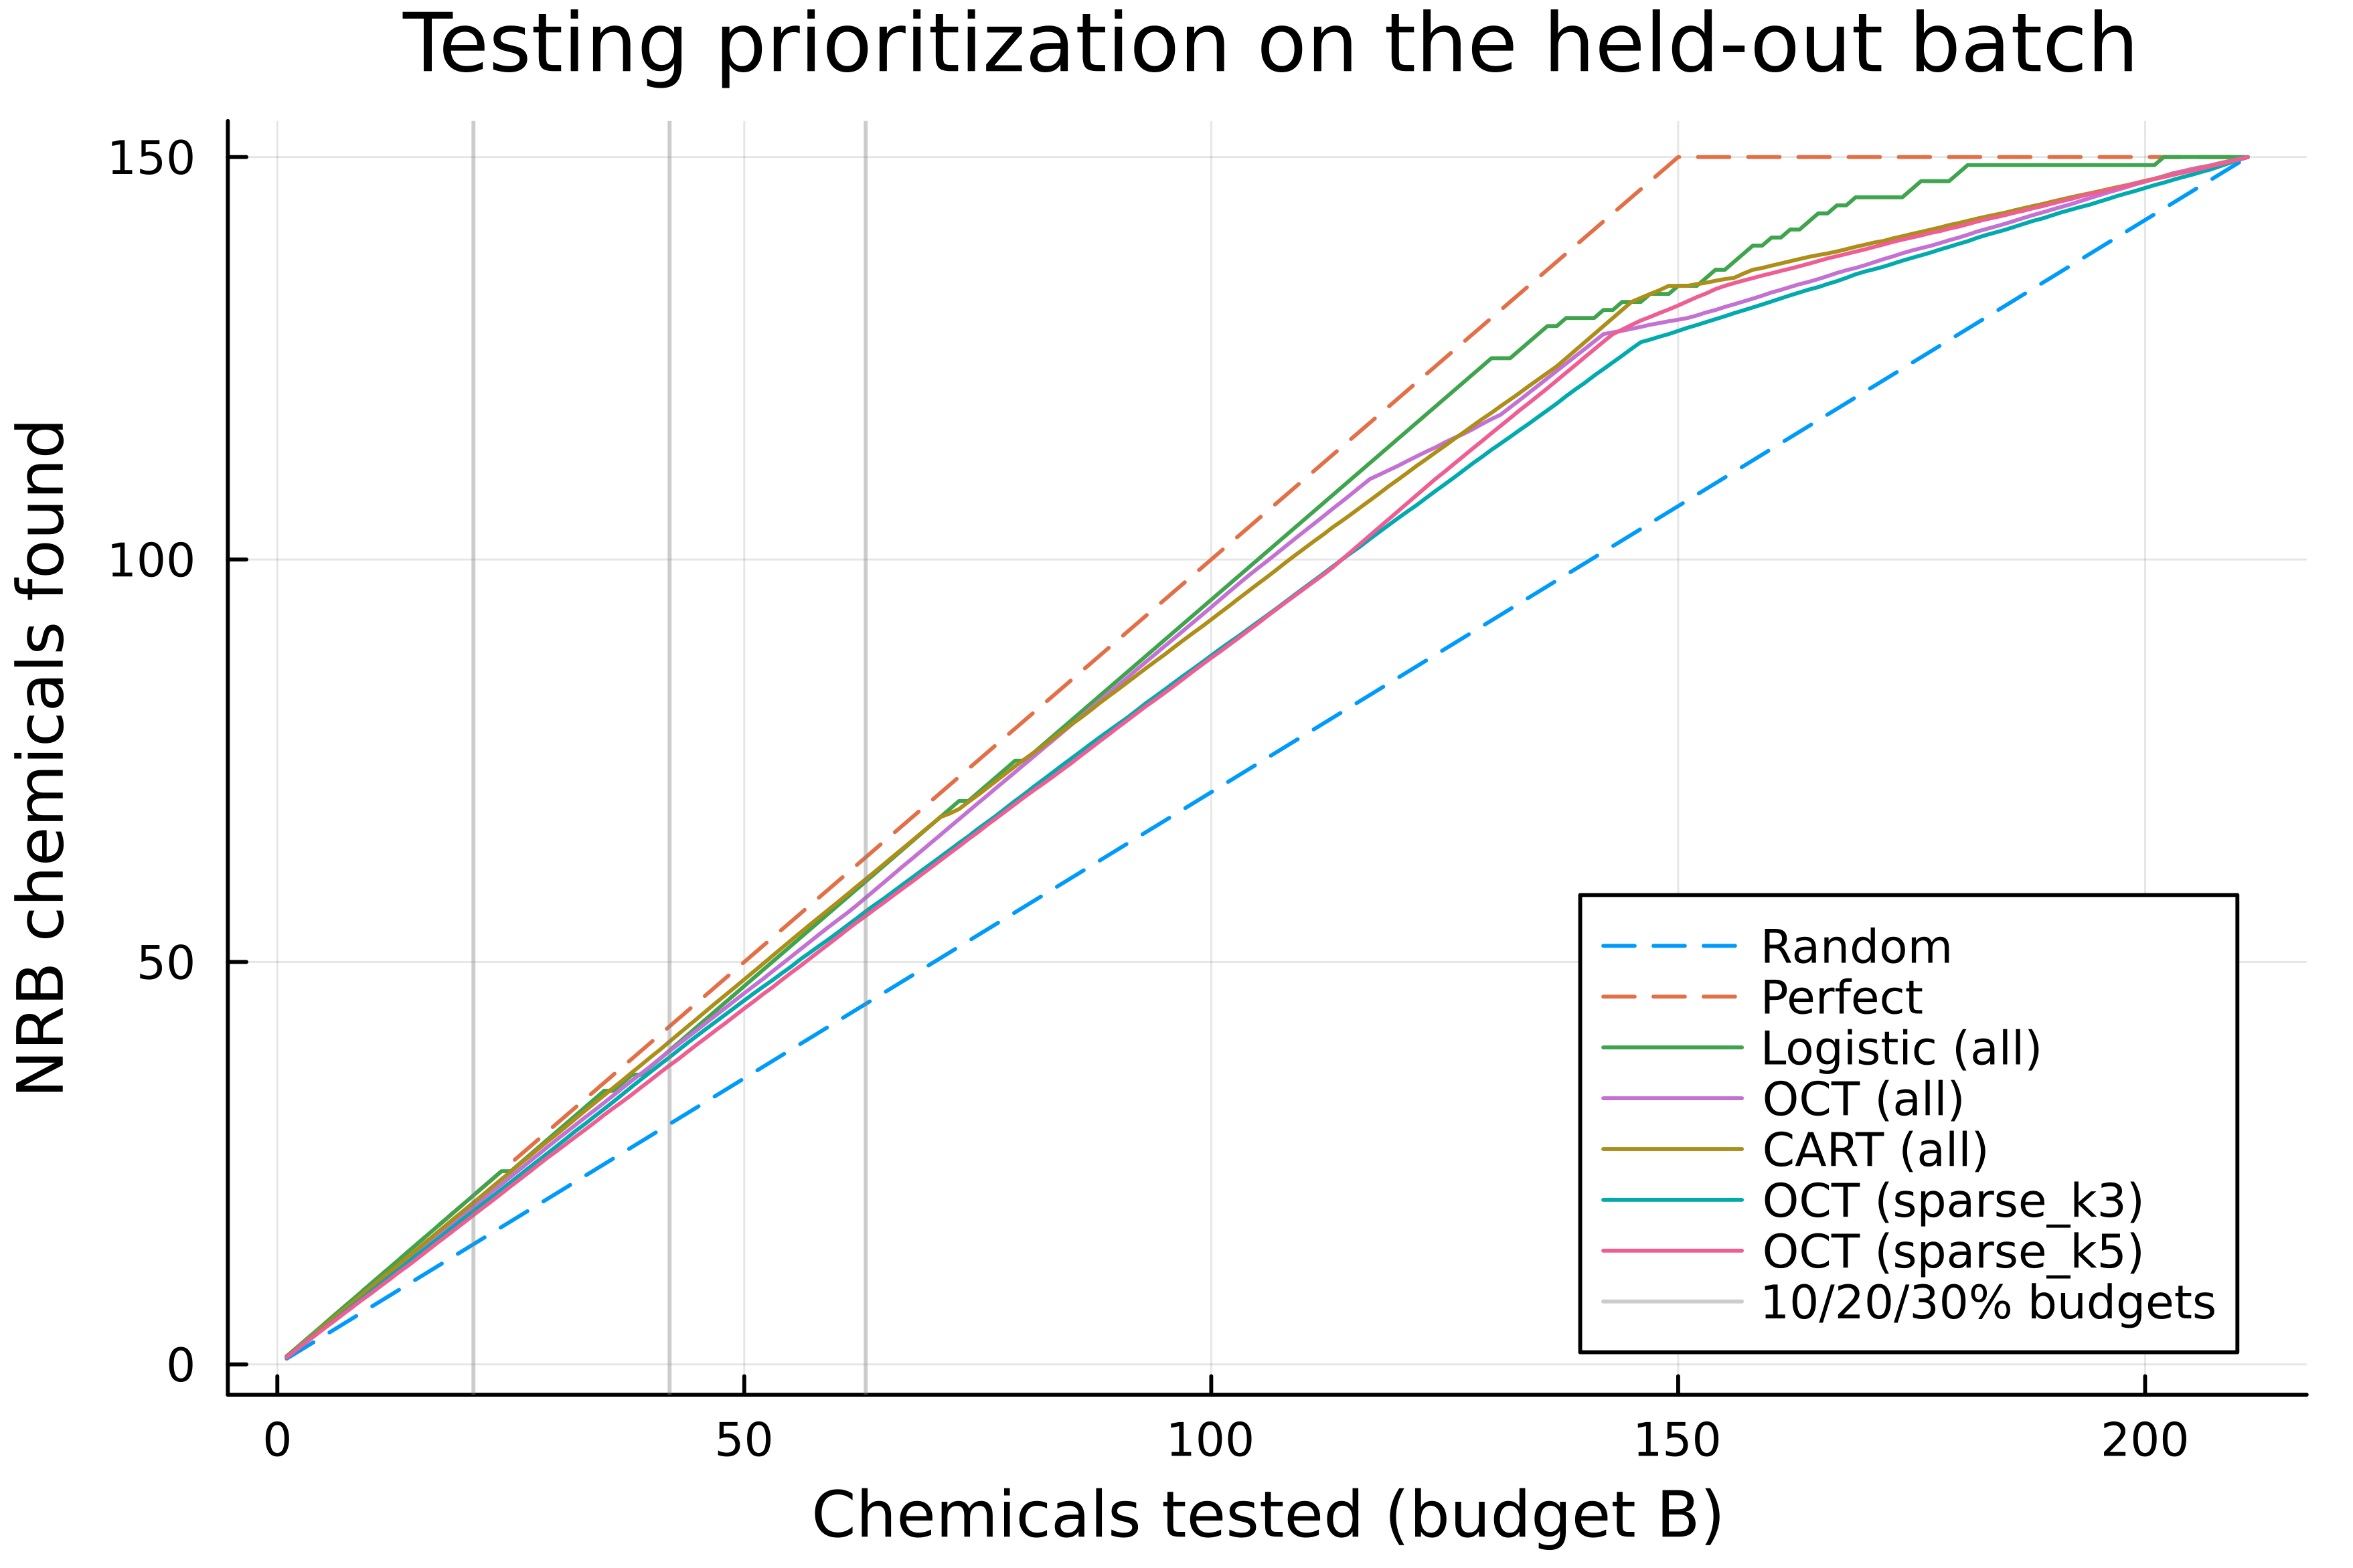

In [19]:
# Optional plot (install once with:  import Pkg; Pkg.add("Plots") )
using Plots
plt = plot(xlabel = "Chemicals tested (budget B)", ylabel = "NRB chemicals found",
           legend = :bottomright, title = "Testing prioritization on the held-out batch")
for c in names(curve)[2:end]
    plot!(plt, curve.B, curve[!, c], label = c,
          linestyle = c in ("Random", "Perfect") ? :dash : :solid)
end
vline!(plt, [round(Int, f * N) for f in BUDGETS], label = "10/20/30% budgets", color = :gray, alpha = 0.4)
savefig(plt, "gains_curve_v4.png")
plt

> ### Reading the plot
> - The dashed **Random** line is the baseline; the dashed **Perfect** line rises at 45° until all NRB chemicals are found.
> - A model's curve is better the closer it hugs the Perfect line early on. **The gap between curves at a given budget is the number of extra NRB chemicals one model finds over another with the same number of tests.**
> - Tree curves rise in straight segments: each segment is one leaf being tested, in random order within the leaf.

---
## Part 13 — Using the model on new chemicals

This turns the frozen models into a **screening tool** someone else could use: give it a table with the same 41 descriptors for new, untested chemicals, and it returns, for each chemical:

- `p_NRB` and the prediction (RB/NRB) at the frozen validation threshold;
- `priority`: rank for testing (1 = test first), i.e. the Part 12 decision;
- `reason` (trees only): the exact path of questions through the tree, so a reviewer can check *why*;
- `outside_training_range`: how many of the model's descriptors fall outside the range seen in training. A simple applicability-domain check: predictions for chemicals unlike the training data are less reliable.

**Practical requirement:** descriptors must be computed exactly as in the original study (same software and definitions), or the thresholds in the tree mean nothing.

The cell also saves the chosen models to files (`IAI.write_json` for trees, a CSV of coefficients and scaling for logistic regression) so they can be loaded later without rerunning this notebook.

In [ ]:
# SCREEN_MODEL = ("all", "OCT")     # which frozen model to use for screening

# lo = Dict(c => minimum(X_tr[!, c]) for c in DESCRIPTORS)
# hi = Dict(c => maximum(X_tr[!, c]) for c in DESCRIPTORS)

# # Path of a chemical through a tree (IAI sends values < threshold to the lower child)
# function explain(lnr, x)
#     n, steps = 1, String[]
#     while !IAI.is_leaf(lnr, n)
#         f = String(IAI.get_split_feature(lnr, n))
#         θ = IAI.get_split_threshold(lnr, n)
#         θs = round(θ, sigdigits = 4)              # rounded for display only
#         v = x[f]
#         if v < θ
#             push!(steps, "$f = $v < $θs");  n = IAI.get_lower_child(lnr, n)
#         else
#             push!(steps, "$f = $v ≥ $θs");  n = IAI.get_upper_child(lnr, n)
#         end
#     end
#     join(steps, "  →  ")
# end

# function screen(newX; key = SCREEN_MODEL)
#     fs = feature_sets[key[1]]
#     obj, thr = models[key]
#     p = scores_on(key, newX)
#     out = DataFrame(chemical = 1:nrow(newX), p_NRB = round.(p, digits = 3),
#                     prediction = ifelse.(p .>= thr, "NRB", "RB"),
#                     priority = invperm(sortperm(p, rev = true)),
#                     outside_training_range = [count(c -> !(lo[c] <= r[c] <= hi[c]), fs)
#                                               for r in eachrow(newX)])
#     key[2] != "Logistic" && (out.reason = [explain(obj, r) for r in eachrow(newX)])
#     sort(out, :priority)
# end

# # Demo: pretend the first 8 test chemicals are new (labels not used)
# show(screen(X_te[1:8, :]), allcols = true, eltypes = false, summary = false, truncate = 0)
# println()

> ### What this shows
> - For each chemical: probability of NRB, the prediction at the frozen threshold, its testing priority, and **the exact path through the tree**, so a reviewer can see why it was flagged.
> - `outside_training_range` counts the model's descriptors that fall outside what training covered. A nonzero value means the chemical is unlike the training data, so its prediction deserves less trust.
> - **Practical limits:** a user must compute the 41 descriptors exactly as the original study did, otherwise the tree thresholds mean nothing; and at about 80% balanced accuracy, this is a screening and prioritization aid, not a replacement for the lab test.

In [ ]:
# # Save the chosen models so they can be reused without this notebook
# for key in [("all", "OCT"), ("sparse_k3", "OCT"), ("all", "CART")]
#     IAI.write_json("model_$(key[1])_$(key[2]).json", models[key][1])
# end
# b, thr = models[("all", "Logistic")]
# CSV.write("model_all_Logistic.csv",
#           DataFrame(term = vcat("intercept", DESCRIPTORS), coefficient = b,
#                     train_mean = vcat(missing, mu), train_sd = vcat(missing, sd)))
# println("Saved. Load a tree later with IAI.read_json(\"model_all_OCT.json\").")

---
## Summary of findings

| Question from the proposal | Answer from this analysis |
|---|---|
| Can a small, understandable OCT perform comparably to more flexible models? | **On classification, yes:** the full OCT (9 leaves, 7 descriptors) ties logistic regression on test balanced accuracy (0.812 each). **On ranking, no:** logistic AUC 0.904 vs. OCT 0.838, because trees give few distinct scores. |
| Does OCT improve on greedy CART? | **Mostly:** OCT beat CART on every sparse feature set, by 0.03–0.05 on test, with fewer leaves; at depth 3 on 3–5 descriptors the gap on validation was large (AUC 0.84–0.86 vs. 0.77). On all features they tie. |
| Does sparse feature selection help? | **No for accuracy:** every model scored best with all 41 descriptors. Linear (L0 least-squares) selection never picked the threshold-type descriptors the trees rely on (SpMax_B(m), F04[C-N]). |
| What do the rules say? | Heavier, more branched, nitrogen-rich or more polarizable molecules tend to fail the screen; small, unbranched, low-nitrogen molecules tend to pass (associations, to be checked against Mansouri et al.). |
| Testing prioritization | See Part 12: the gain over random selection is capped at about 1.4× because the batch is 71% NRB; ranking quality decides who wins. |

**Limitations:** one random (non-stratified) split with small validation and test sets (211 each, about ±0.03 noise); thresholds tuned on validation transferred poorly for logistic regression with few descriptors; choosing among many options on validation rewards luck (the CART pick fell from 0.817 to 0.718); and the prioritization step is a ranking exercise with equal costs.